# Problem Statement :   CardioGood Fitness Data Analysis

## Context
 The market research team at AdRight is assigned the task to identify the profile of the typical customer for each treadmill product offered by CardioGood Fitness. The market research team decides to investigate whether there are differences across the product lines with respect to customer characteristics. The team decides to collect data on individuals who purchased a treadmill at a CardioGood Fitness retail store at any time in the past three months. The data is stored in the CardioGoodFitness.csv file.

## Objective
 Perform descriptive analysis to create a customer profile for each CardioGood Fitness treadmill product line.

## Data Dictionary

**The team identified the following customer variables to study:**

* Product: Product purchased - TM195, TM498, or TM798
* Gender: Male or Female
* Age: Age of the customer in years
* Education: Education of the customer in years
* MaritalStatus: Single or partnered
* Income: Annual household income
* Usage: The average number of times the customer plans to use the treadmill each week;
* Miles: The average number of miles the customer expects to walk/run each week;
* Fitness: Self-rated fitness on a 1-to-5 scale, where 1 is the poor shape and 5 is excellent shape.

## Questions to explore
* What are the different types of variables in the data?
* What is the distribution of different variables in the data?
* Which product is more popular among males or females?
* Is the product purchase affected by the marital status of the customer?
* Is there a significant correlation among some of the variables?
* What is the distribution of the average number of miles for each product?

In [1]:
#load necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
from pathlib import Path

# Reads the CSV from the repo's data/ folder; falls back to GitHub if run on Colab without the file
RAW = "https://raw.githubusercontent.com/Bilal-Butt/CardioGood-Fitness-Data-Analysis/main/data/CardioGoodFitness.csv"
local = next((p / "CardioGoodFitness.csv" for p in (Path("../data"), Path("data"), Path(".")) if (p / "CardioGoodFitness.csv").exists()), None)
mydata = pd.read_csv(local if local else RAW)

In [3]:
# read data
mydata.head()

,Product,Age,Gender,Education,MaritalStatus,Usage,Fitness,Income,Miles
0,TM195,18,Male,14,Single,3,4,29562,112
1,TM195,19,Male,15,Single,2,3,31836,75
2,TM195,19,Female,14,Partnered,4,3,30699,66
3,TM195,19,Male,12,Single,3,3,32973,85
4,TM195,20,Male,13,Partnered,4,2,35247,47


In [4]:
#generate Analytical summery of all the data
mydata.describe(include = 'all')

,Product,Age,Gender,Education,MaritalStatus,Usage,Fitness,Income,Miles
count,180,180.000000,180,180.000000,180,180.000000,180.000000,180.000000,180.000000
unique,3,NaN,2,NaN,2,NaN,NaN,NaN,NaN
top,TM195,NaN,Male,NaN,Partnered,NaN,NaN,NaN,NaN
freq,80,NaN,104,NaN,107,NaN,NaN,NaN,NaN
mean,NaN,28.788889,NaN,15.572222,NaN,3.455556,3.311111,53719.577778,103.194444
std,NaN,6.943498,NaN,1.617055,NaN,1.084797,0.958869,16506.684226,51.863605
min,NaN,18.000000,NaN,12.000000,NaN,2.000000,1.000000,29562.000000,21.000000
25%,NaN,24.000000,NaN,14.000000,NaN,3.000000,3.000000,44058.750000,66.000000
50%,NaN,26.000000,NaN,16.000000,NaN,3.000000,3.000000,50596.500000,94.000000
75%,NaN,33.000000,NaN,16.000000,NaN,4.000000,4.000000,58668.000000,114.750000


In [5]:
print(f"Number of rows and columns: {mydata.shape}")

# Detailed structural summary of the data
mydata.info()

Number of rows and columns: (180, 9)
<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Product        180 non-null    str  
 1   Age            180 non-null    int64
 2   Gender         180 non-null    str  
 3   Education      180 non-null    int64
 4   MaritalStatus  180 non-null    str  
 5   Usage          180 non-null    int64
 6   Fitness        180 non-null    int64
 7   Income         180 non-null    int64
 8   Miles          180 non-null    int64
dtypes: int64(6), str(3)
memory usage: 12.8 KB


In [6]:
# Data quality checks
print("Missing values:", mydata.isna().sum().sum())
print("Duplicate rows:", mydata.duplicated().sum())
print("\nCustomers per product:")
print(mydata["Product"].value_counts())

Missing values: 0
Duplicate rows: 0

Customers per product:
Product
TM195    80
TM498    60
TM798    40
Name: count, dtype: int64


**Data overview.** 180 customers and 9 columns, with **no missing values and no duplicate rows**. Six variables are numeric (Age, Education, Usage, Fitness, Income, Miles; Usage and Fitness are ordinal scores) and three are categorical (Product, Gender, MaritalStatus). TM195 is the most purchased product (80 customers, 44%), followed by TM498 (60, 33%) and TM798 (40, 22%).

array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Education'}>],
       [<Axes: title={'center': 'Usage'}>,
        <Axes: title={'center': 'Fitness'}>],
       [<Axes: title={'center': 'Income'}>,
        <Axes: title={'center': 'Miles'}>]], dtype=object)

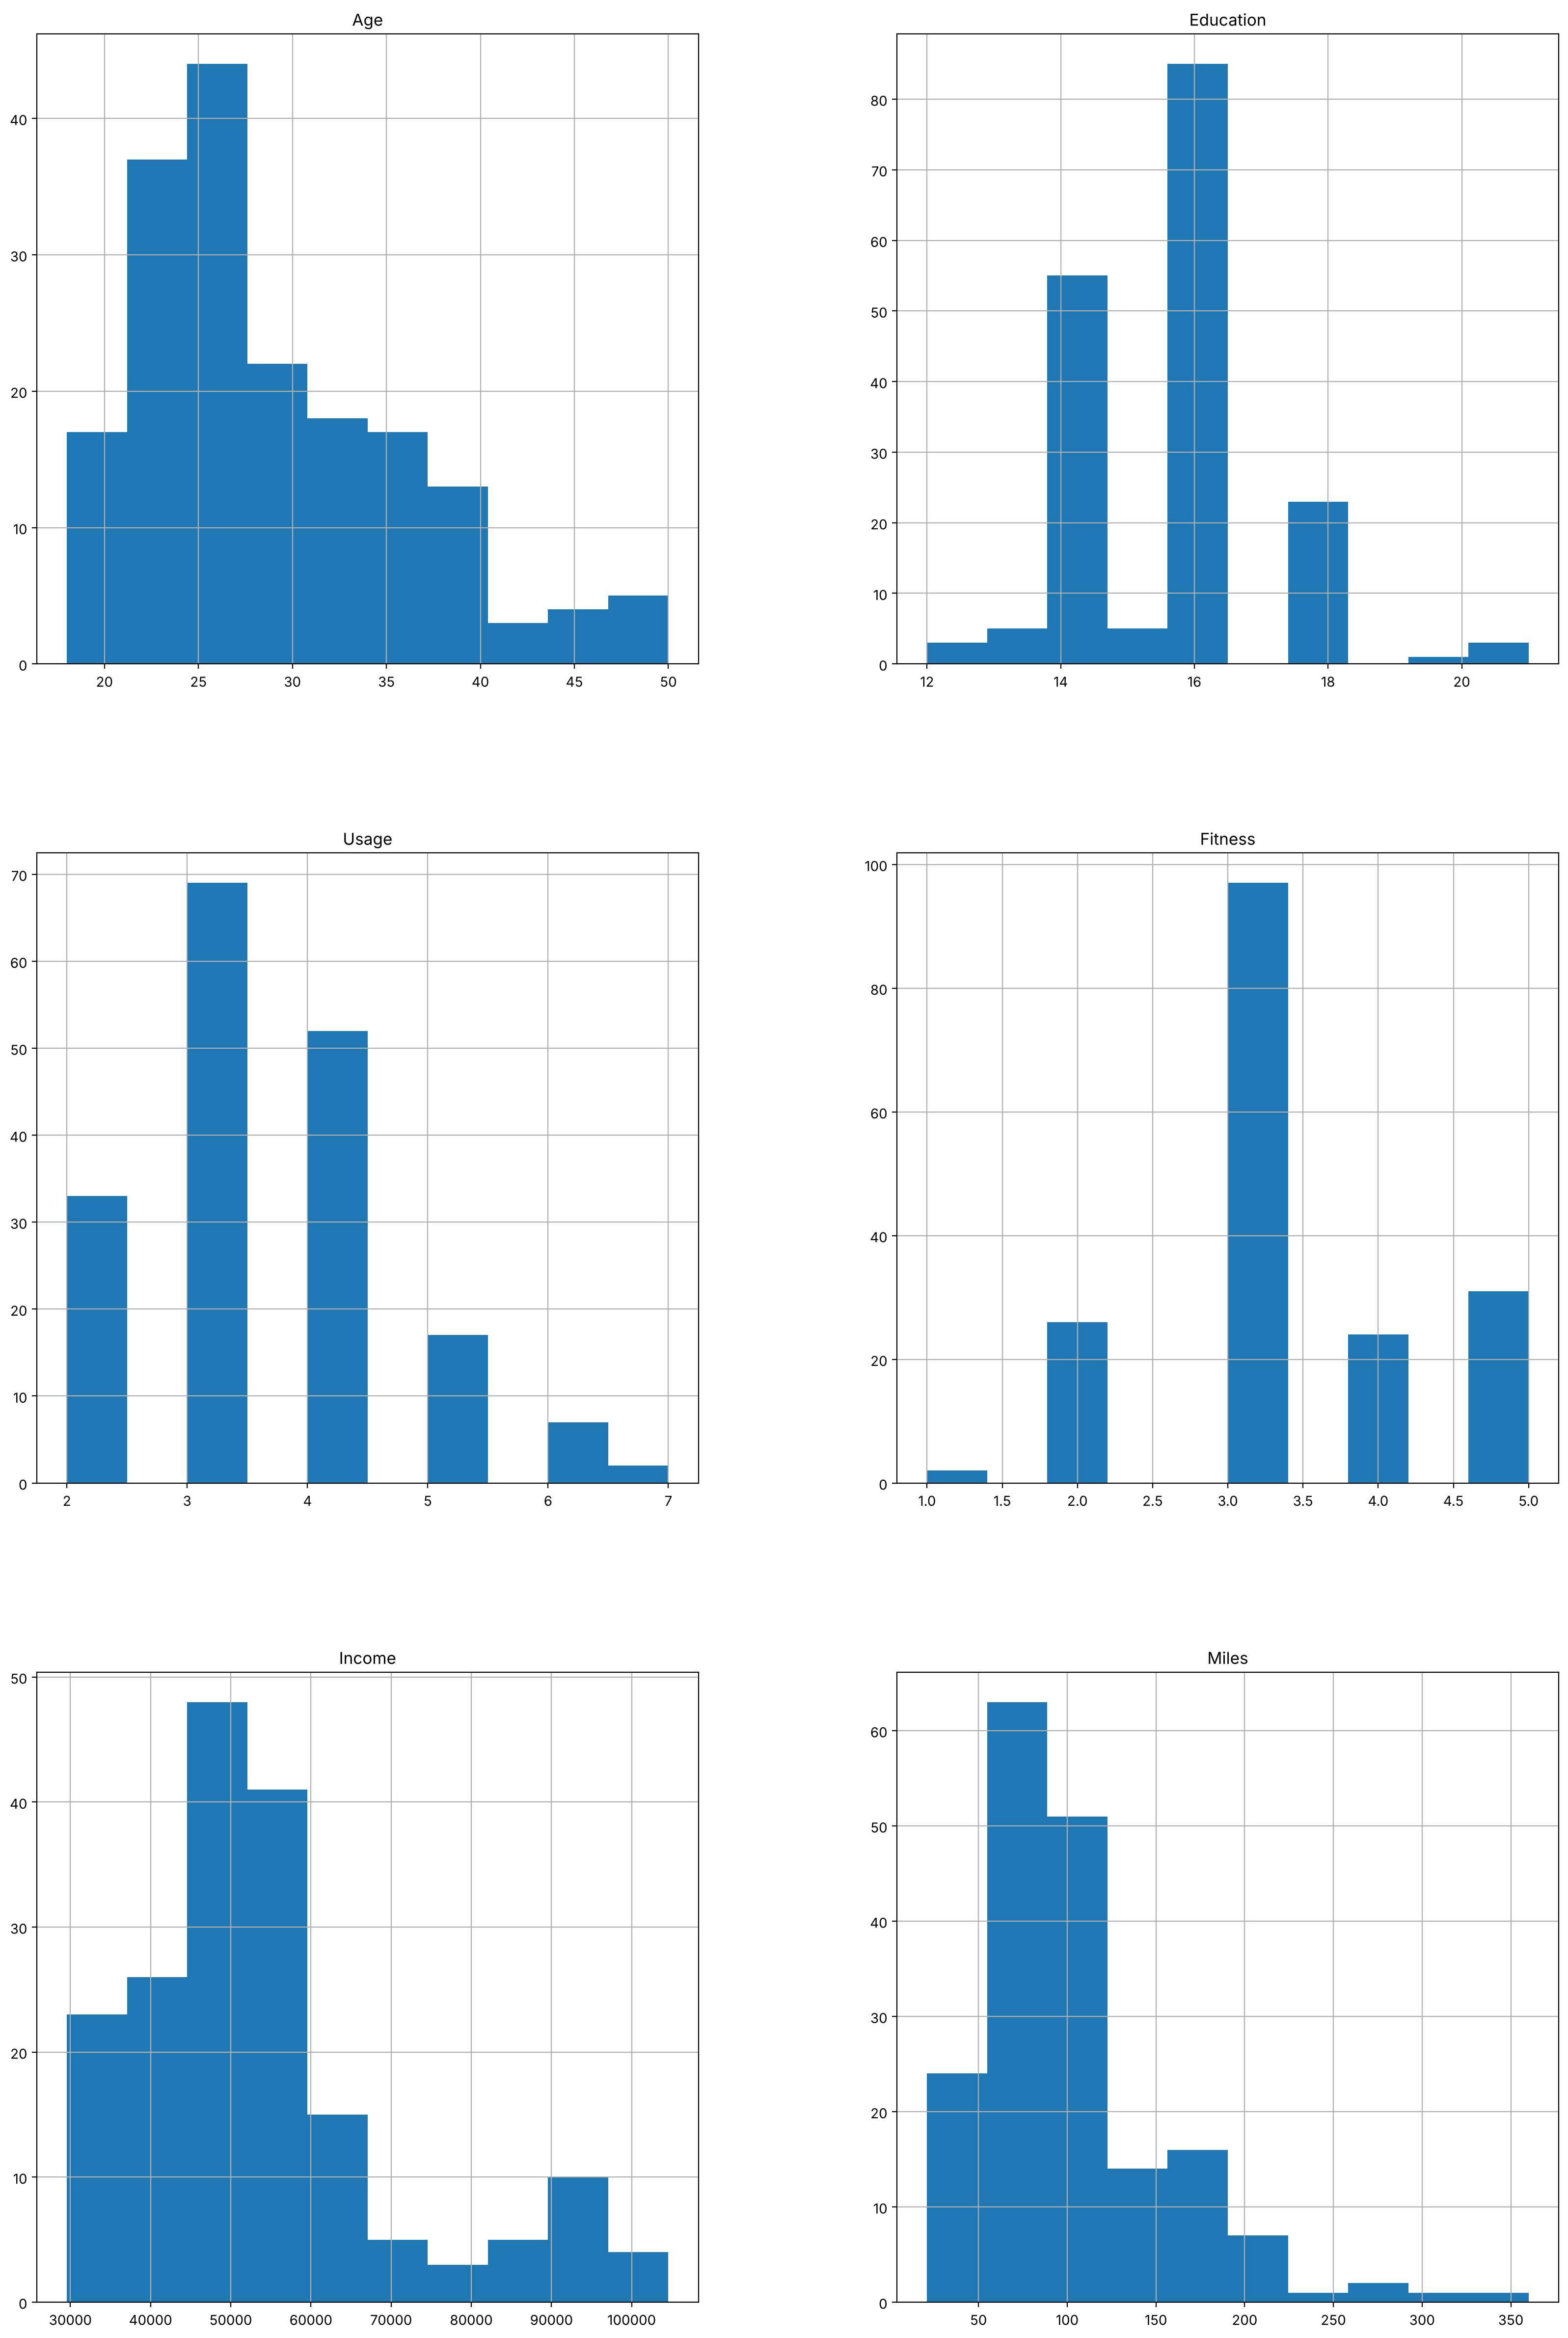

In [7]:
mydata.hist(figsize = (20,30))

**Distributions.** Age, Income and Miles are right-skewed: most customers are in their 20s (mean 28.8, median 26, range 18-50), income has a mean of \$53.7k vs a median of \$50.6k (maximum \$104.6k), and weekly miles has a median of 94 with a long tail up to 360. Most customers plan to use the treadmill 3-4 times a week (121 of 180) and rate their fitness as 3 (97 of 180).

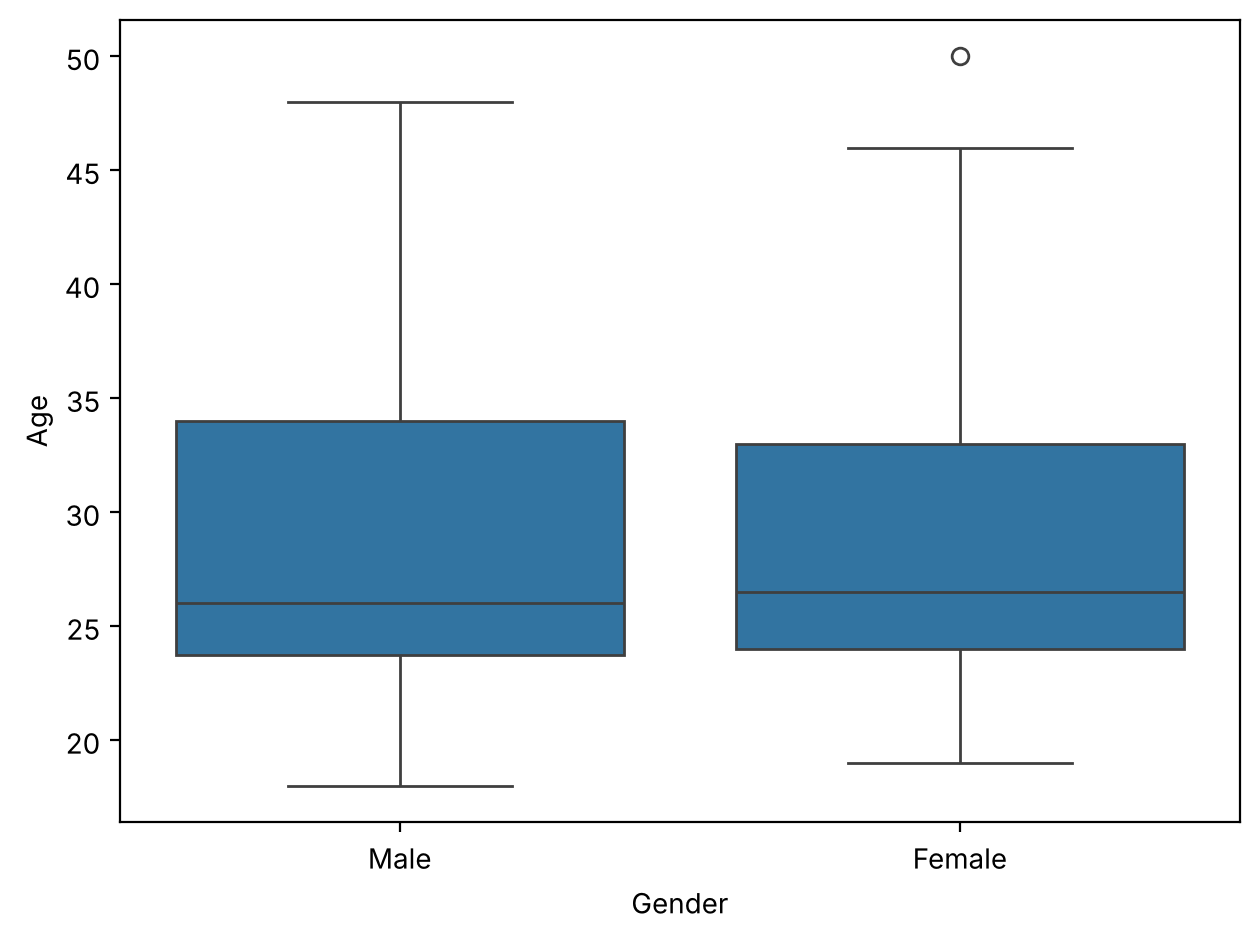

In [8]:
sns.boxplot(x ='Gender', y ='Age',data = mydata )
plt.tight_layout()
plt.show()

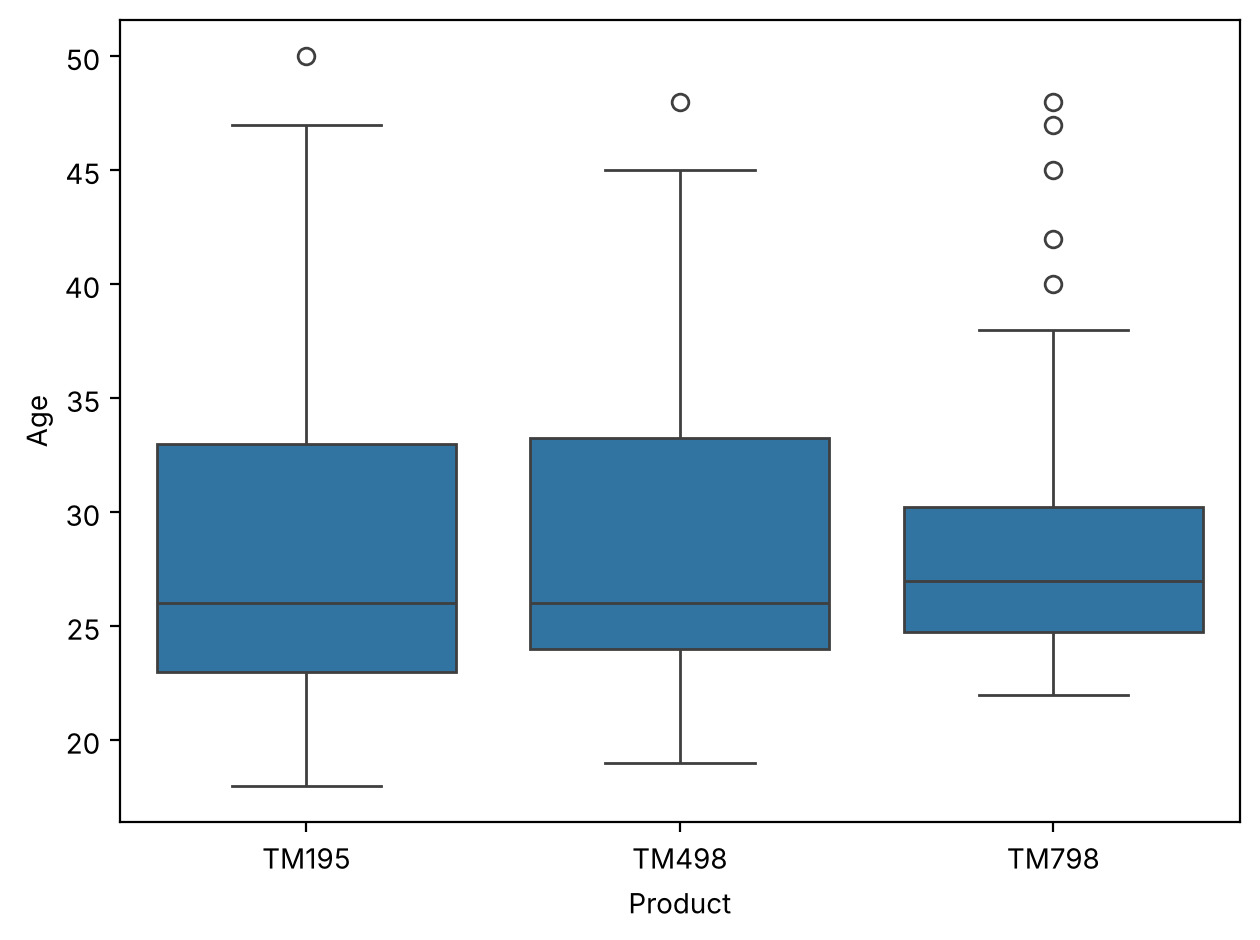

In [9]:
sns.boxplot(x='Product',y ='Age', data = mydata)
plt.tight_layout()
plt.show()

**Age by gender and product.** Age distributions are very similar for men and women (mean 29.0 vs 28.6), and across the three products (product means 28.6, 28.9 and 29.1 years). Age does not distinguish the product lines (one-way ANOVA p = 0.91, shown later).

In [10]:
pd.crosstab(mydata['Product'],mydata['Gender'])

Gender,Female,Male
Product,,
TM195,40,40
TM498,29,31
TM798,7,33


In [11]:
pd.crosstab(mydata['Product'],mydata['MaritalStatus'])

MaritalStatus,Partnered,Single
Product,,
TM195,48,32
TM498,36,24
TM798,23,17


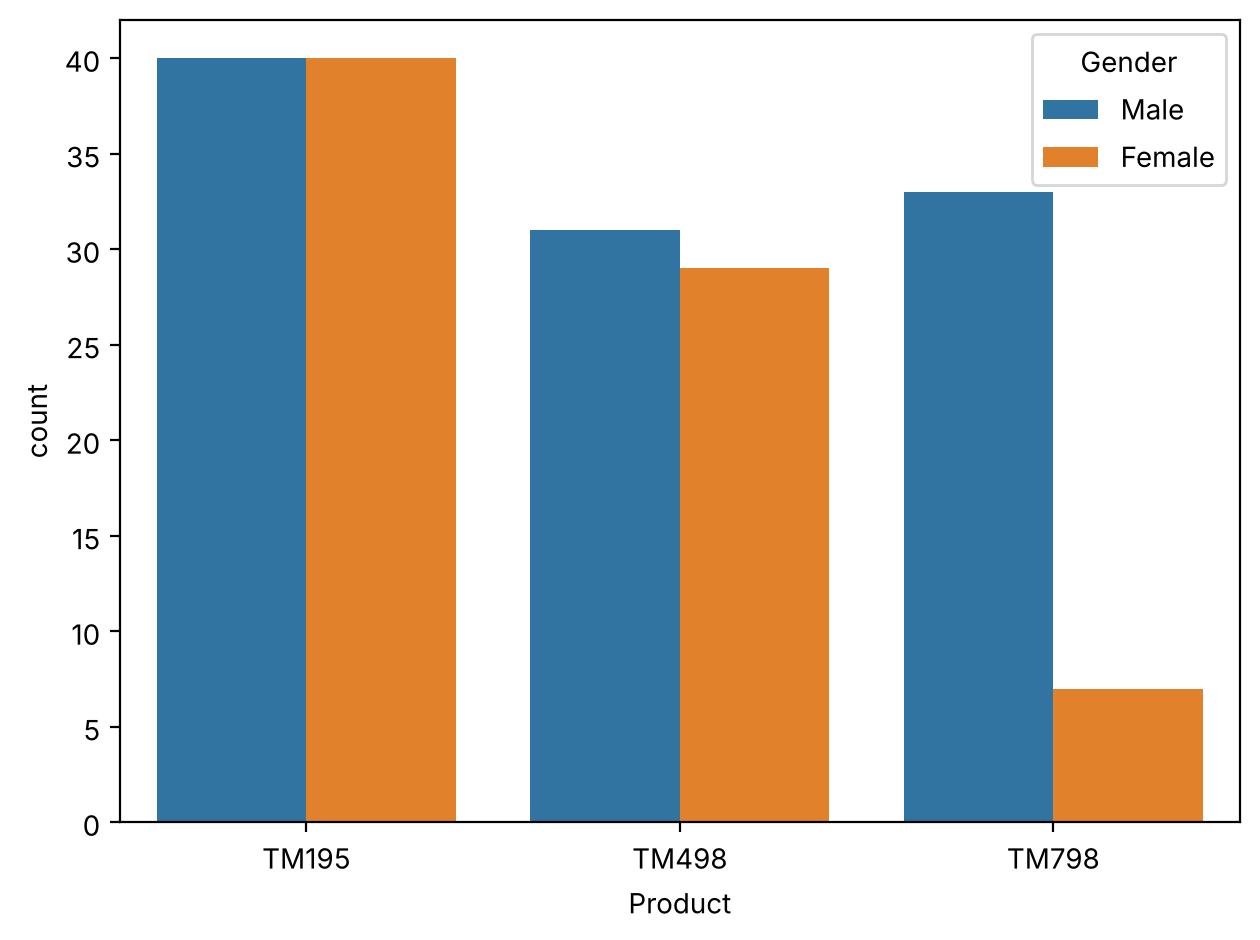

In [12]:
sns.countplot(x='Product',hue='Gender',data = mydata)
plt.tight_layout()
plt.show()

**Product by gender.** TM195 is split evenly (40 women, 40 men) and TM498 almost evenly (29 / 31), but TM798 is strongly male-dominated (7 women, 33 men: 82.5% male). A chi-square test confirms the association (p = 0.002, shown later).

In [13]:
pd.pivot_table(mydata, index=['Product','Gender'],
               columns=['MaritalStatus'],aggfunc='count')

Age        Education          Fitness           Income  \
MaritalStatus  Partnered Single Partnered Single Partnered Single Partnered   
Product Gender                                                                
TM195   Female        27     13        27     13        27     13        27   
        Male          21     19        21     19        21     19        21   
TM498   Female        15     14        15     14        15     14        15   
        Male          21     10        21     10        21     10        21   
TM798   Female         4      3         4      3         4      3         4   
        Male          19     14        19     14        19     14        19   

                          Miles            Usage         
MaritalStatus  Single Partnered Single Partnered Single  
Product Gender                                           
TM195   Female     13        27     13        27     13  
        Male       19        21     19        21     19  
TM498   Female     14        15     14        15     14  
        Male       10        21     10        21     10  
TM798   Female      3         4      3         4      3  
        Male       14        19     14        19     14

In [14]:
pd.pivot_table(mydata,'Income',index=['Product' ,'Gender'],
               columns = ['MaritalStatus'])

MaritalStatus      Partnered        Single
Product Gender                            
TM195   Female  46153.777778  45742.384615
        Male    50028.000000  43265.842105
TM498   Female  49724.800000  48920.357143
        Male    49378.285714  47071.800000
TM798   Female  84972.250000  58516.000000
        Male    81431.368421  68216.428571

In [15]:
pd.pivot_table(mydata,'Miles',index=['Product','Gender'],columns = ['MaritalStatus'])

MaritalStatus    Partnered      Single
Product Gender                        
TM195   Female   74.925926   78.846154
        Male     80.190476   99.526316
TM498   Female   94.000000   80.214286
        Male     87.238095   91.100000
TM798   Female  215.000000  133.333333
        Male    176.315789  147.571429

**Segment pivots (Product x Gender x Marital status).** TM798 buyers have the highest mean income (about \$74-76k vs \$46-49k) and the highest weekly miles in every gender/marital group. Within each product, men and women earn similar incomes, so the overall male-female income gap (\$56.6k vs \$49.8k) mostly reflects more men buying the higher-income TM798 rather than a gap within products. Some cells are very small (for example only 4 partnered and 3 single women bought TM798), so single-cell averages should be read cautiously.

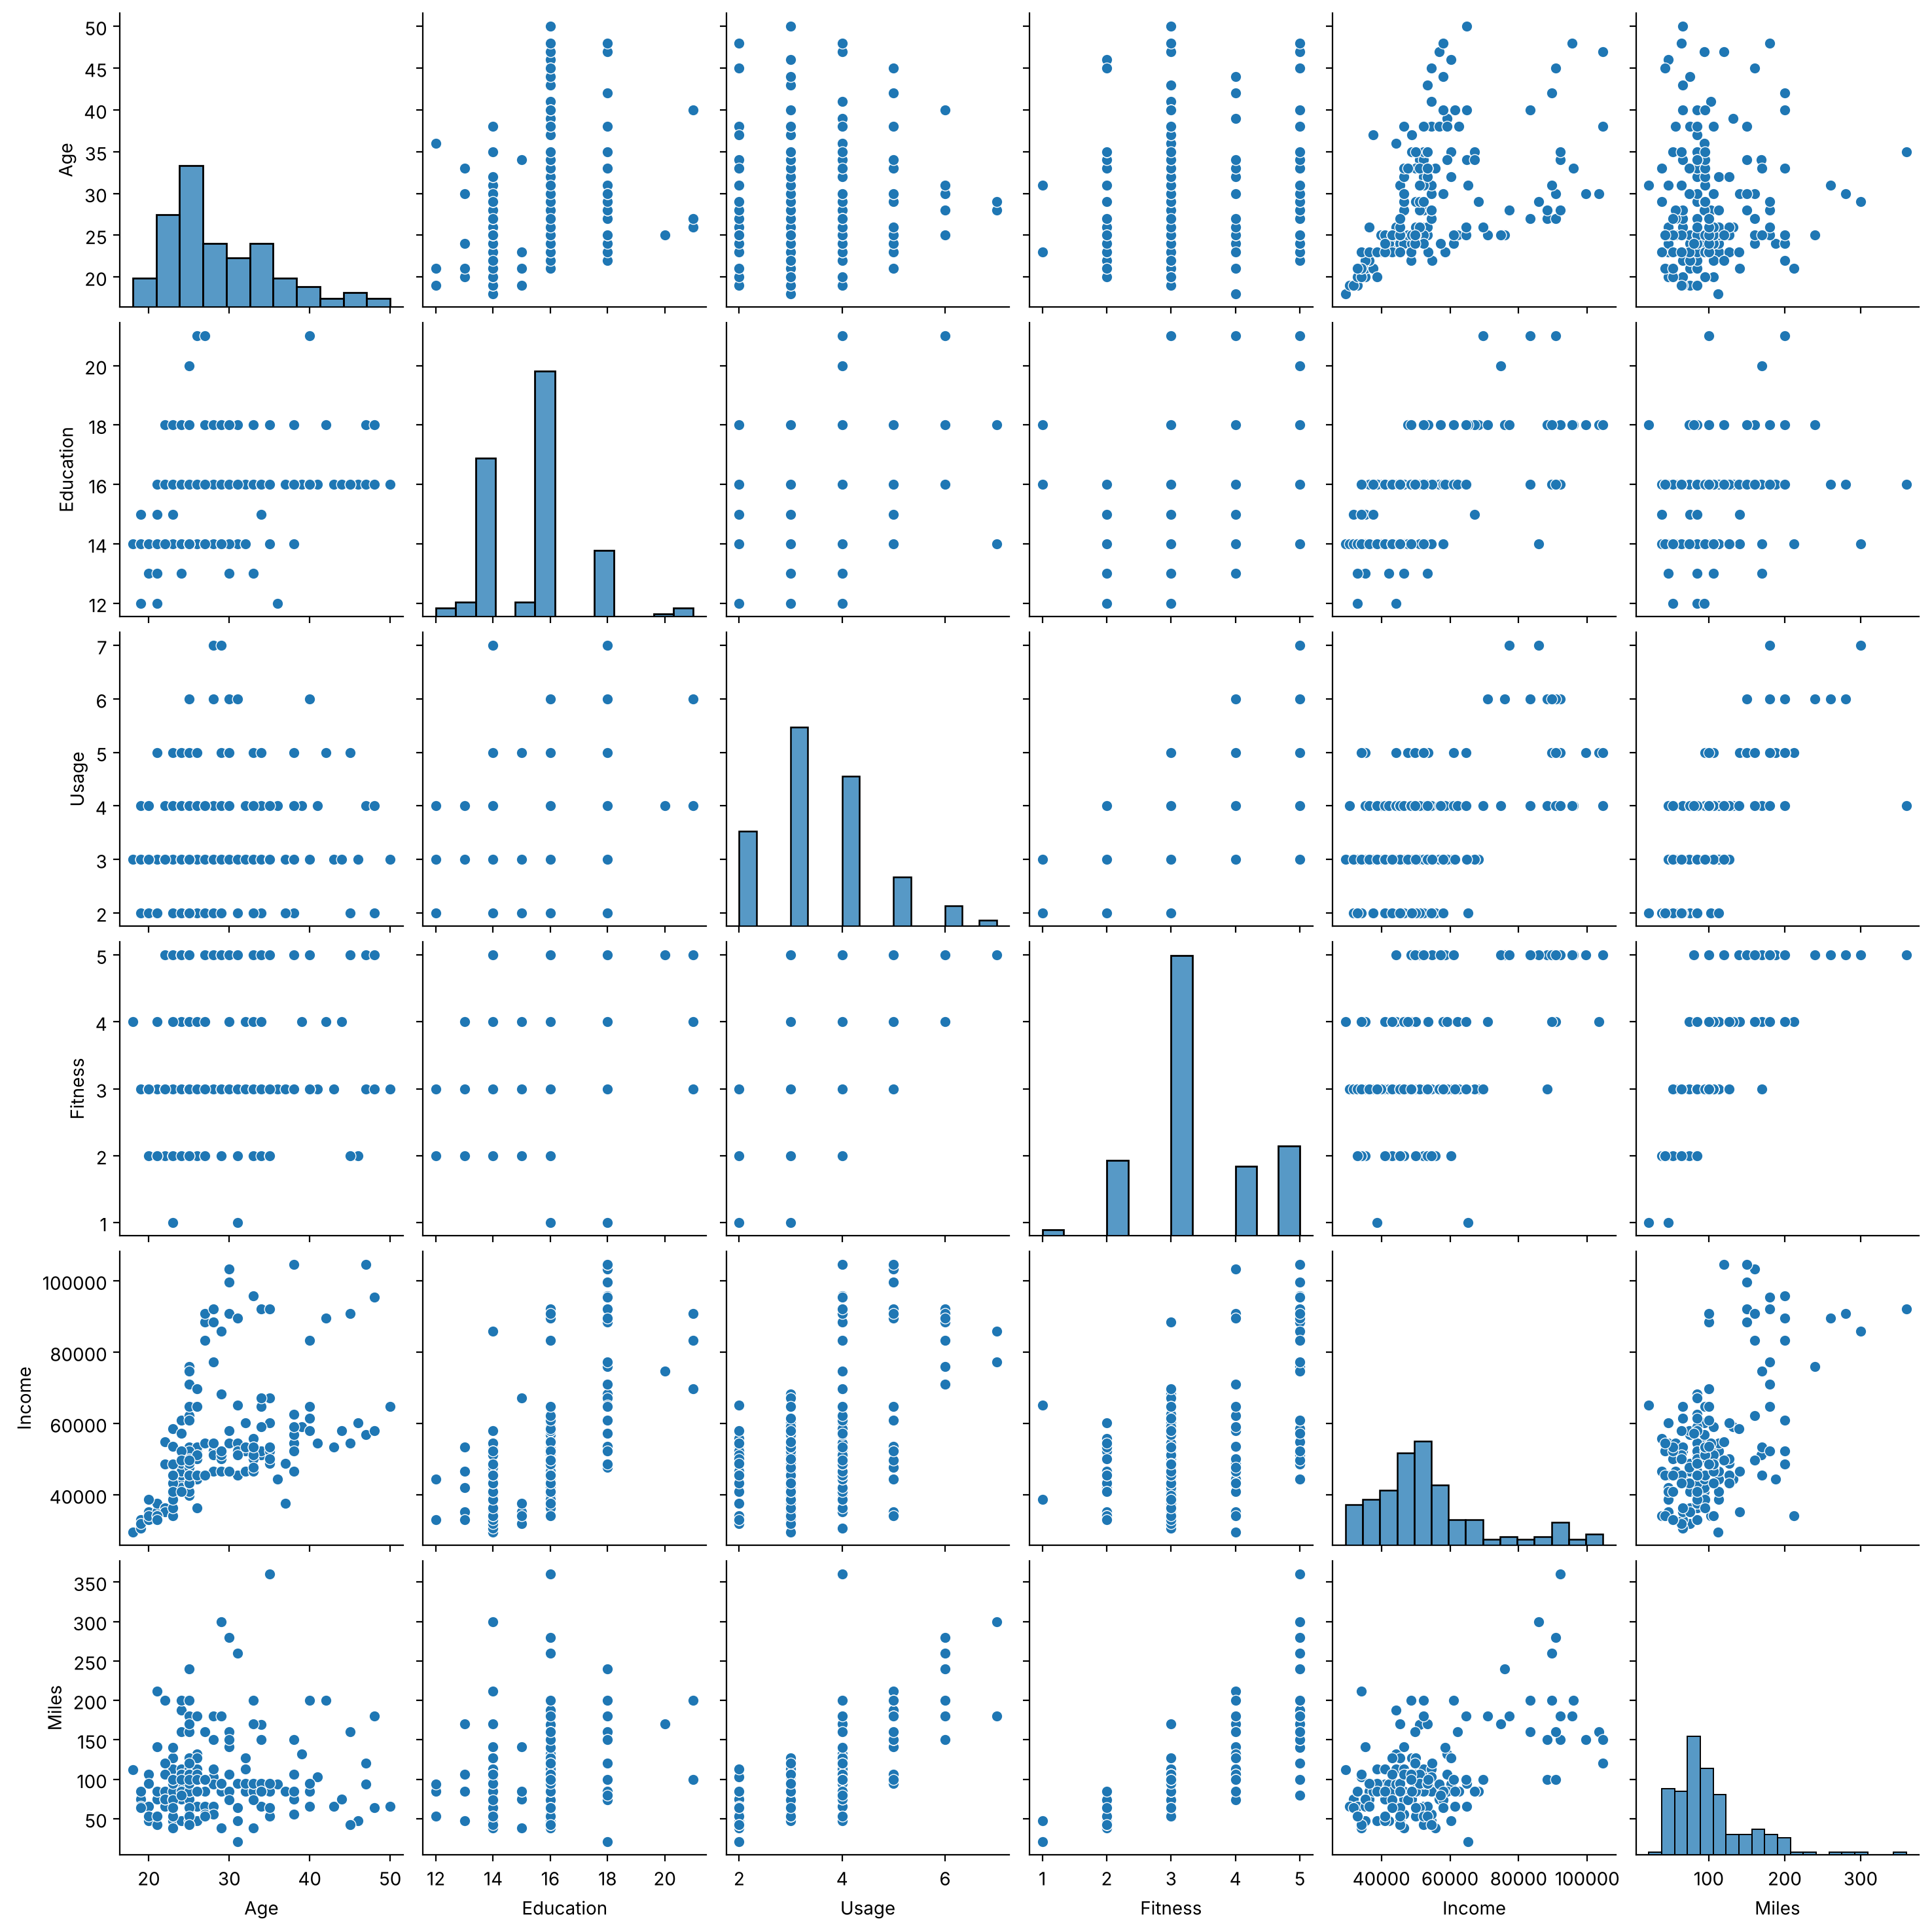

In [16]:
sns.pairplot(mydata);

**Pairplot.** Miles rises with Usage and Fitness, and Income rises with Education and Age. Age shows almost no relationship with Usage, Fitness or Miles. The relationships look broadly linear and positive; the plot is not coloured by product, so product differences are examined separately below.

In [17]:
mydata['Age'].std()

np.float64(6.943498135399795)

In [18]:
mydata['Age'].mean()

np.float64(28.788888888888888)

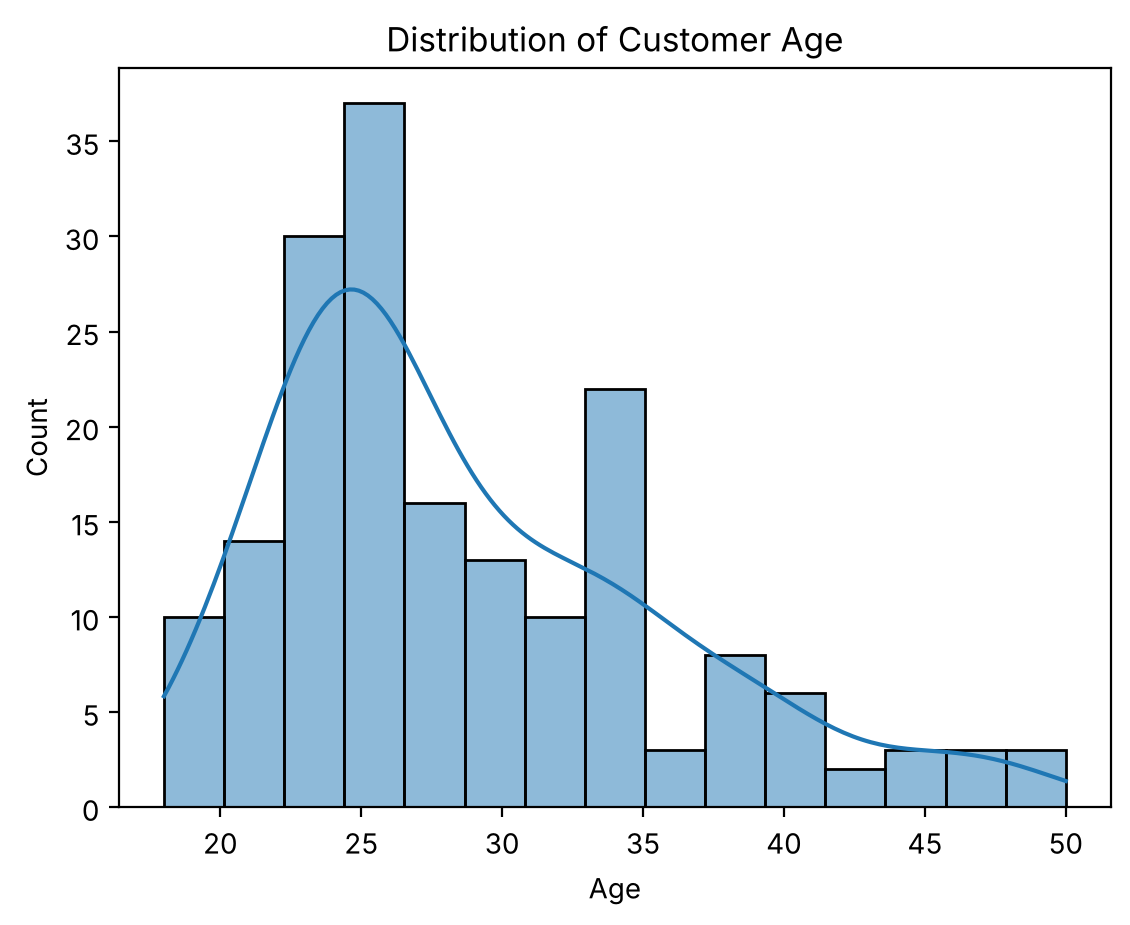

In [19]:
sns.histplot(mydata['Age'], kde=True, bins=15)
plt.title('Distribution of Customer Age')
plt.show()

**Age histogram.** Most customers are between 20 and 35, with a long tail to 50 (mean 28.8, standard deviation 6.9).

array([<Axes: title={'center': 'Female'}>,
       <Axes: title={'center': 'Male'}>], dtype=object)

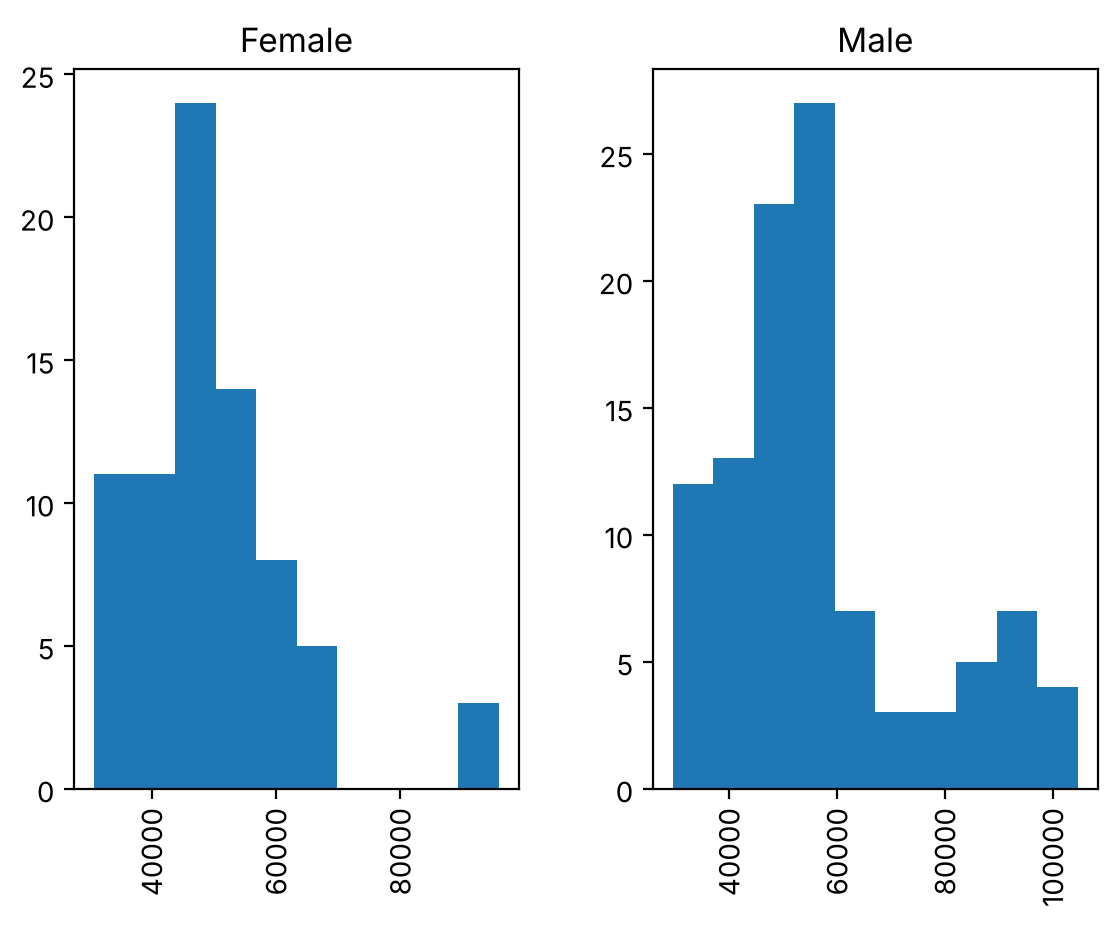

In [20]:
mydata.hist(by = 'Gender',column = 'Income')

**Income by gender.** Both distributions are right-skewed. Men have higher incomes on average (\$56.6k vs \$49.8k) and a higher maximum (\$104.6k vs \$95.9k). As the pivots above show, this gap is explained by product mix, not by a gap within products.

In [21]:
# Compute correlation matrix only for numeric columns
corr = mydata.corr(numeric_only=True)
corr

,Age,Education,Usage,Fitness,Income,Miles
Age,1.000000,0.280496,0.015064,0.061105,0.513414,0.036618
Education,0.280496,1.000000,0.395155,0.410581,0.625827,0.307284
Usage,0.015064,0.395155,1.000000,0.668606,0.519537,0.759130
Fitness,0.061105,0.410581,0.668606,1.000000,0.535005,0.785702
Income,0.513414,0.625827,0.519537,0.535005,1.000000,0.543473
Miles,0.036618,0.307284,0.759130,0.785702,0.543473,1.000000


In [22]:
cov = mydata.cov(numeric_only=True)
cov

,Age,Education,Usage,Fitness,Income,Miles
Age,48.212166,3.149410,0.113470,0.406828,5.884446e+04,13.186530
Education,3.149410,2.614867,0.693172,0.636623,1.670472e+04,25.770795
Usage,0.113470,0.693172,1.176785,0.695469,9.303043e+03,42.709808
Fitness,0.406828,0.636623,0.695469,0.919429,8.467925e+03,39.073246
Income,58844.463439,16704.717815,9303.042582,8467.925388,2.724706e+08,465265.361887
Miles,13.186530,25.770795,42.709808,39.073246,4.652654e+05,2689.833489


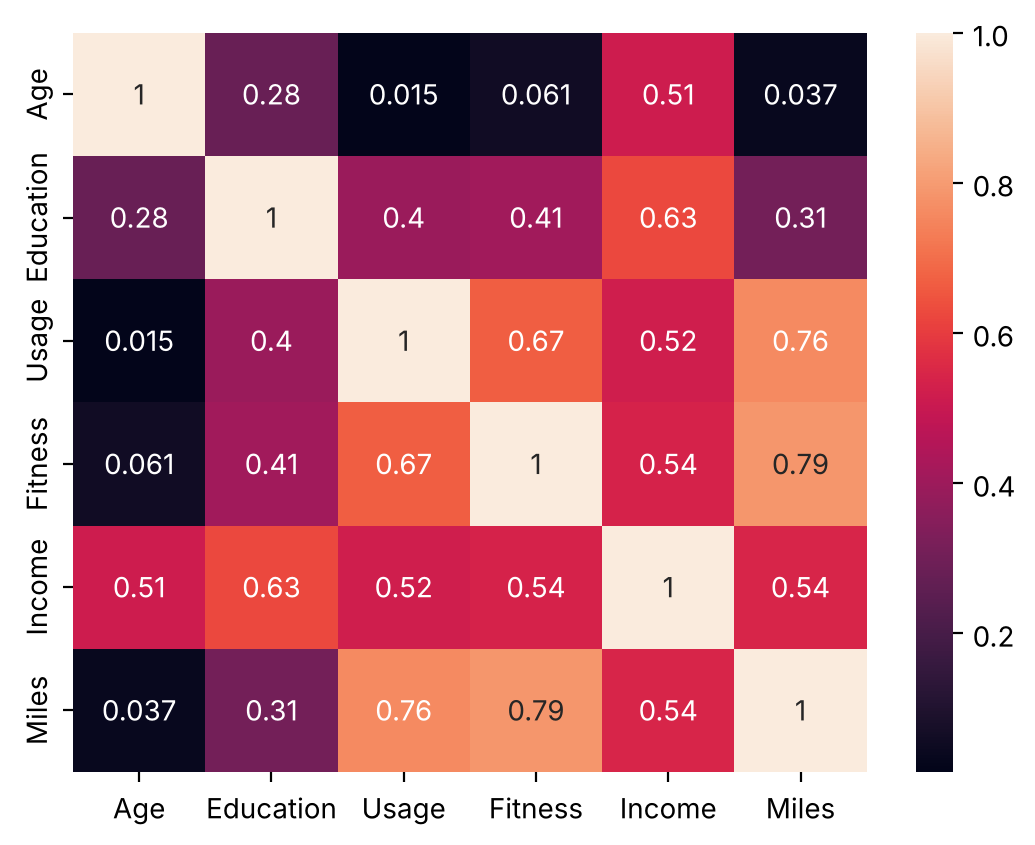

In [23]:
sns.heatmap(corr,annot=True);

**Correlations.** The strongest relationships are Fitness-Miles (0.79), Usage-Miles (0.76) and Usage-Fitness (0.67). Education-Income (0.63), Age-Income (0.51) and Income-Miles (0.54) are moderate. Age is essentially uncorrelated with Usage, Fitness and Miles (0.02-0.06). Usage and Fitness are themselves correlated, so their separate effects on Miles overlap. Correlation does not imply causation.

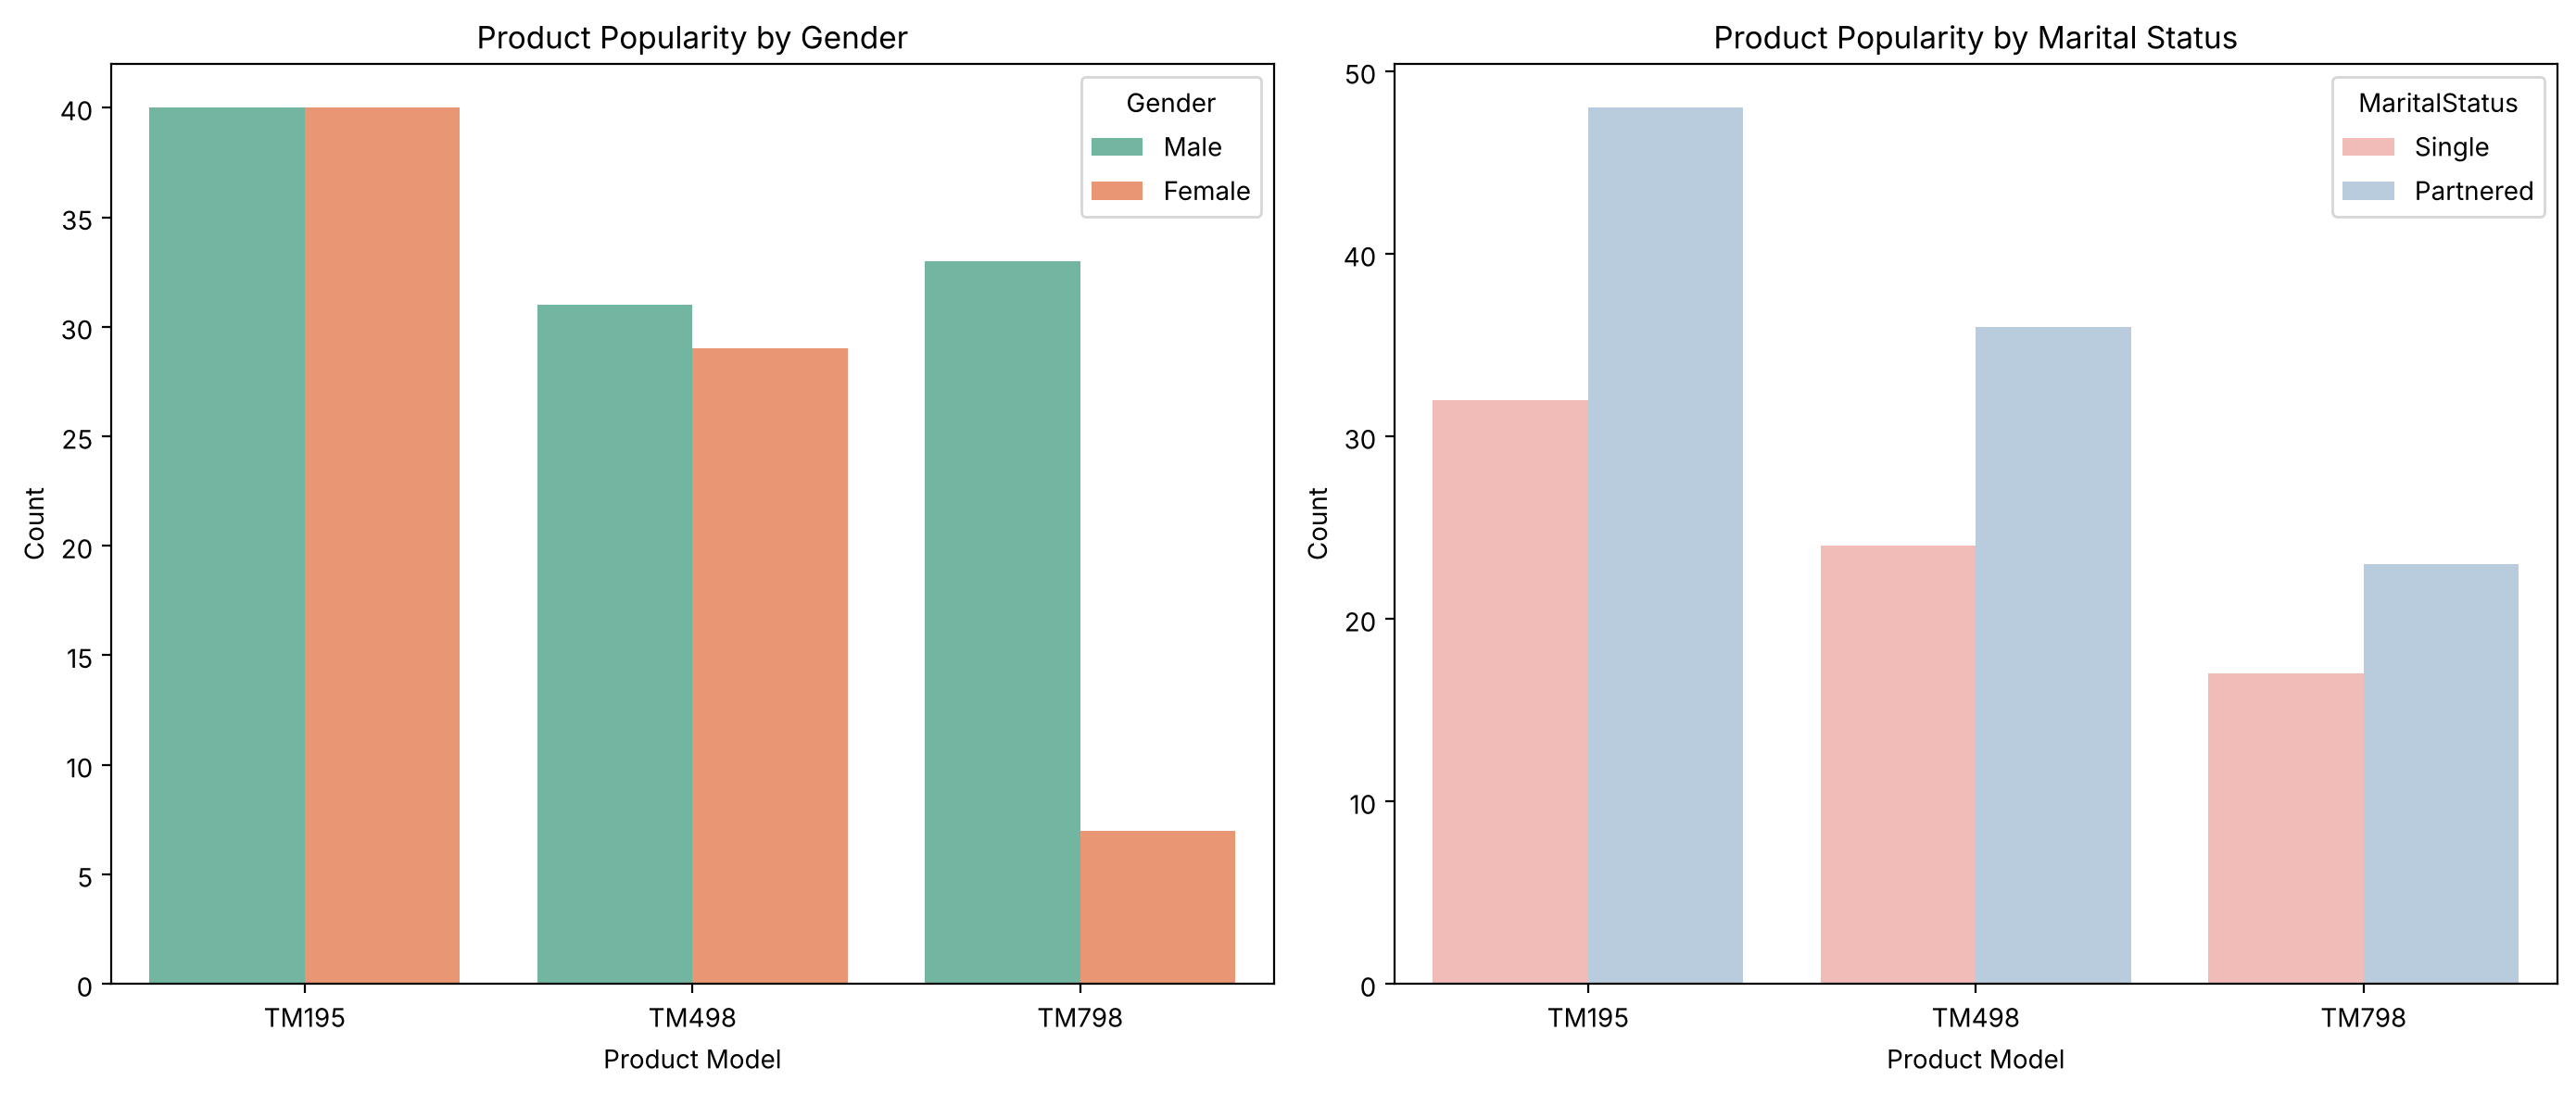

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Product popularity by Gender
sns.countplot(data=mydata, x='Product', hue='Gender', ax=axes[0], palette='Set2')
axes[0].set_title('Product Popularity by Gender')
axes[0].set_xlabel('Product Model')
axes[0].set_ylabel('Count')

# Plot 2: Product popularity by Marital Status
sns.countplot(data=mydata, x='Product', hue='MaritalStatus', ax=axes[1], palette='Pastel1')
axes[1].set_title('Product Popularity by Marital Status')
axes[1].set_xlabel('Product Model')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

## Customer profile by product

The objective is a profile of the typical buyer of each treadmill. The table below summarises each product, followed by statistical tests of whether the differences are real or could be chance (alpha = 0.05).

In [25]:
profile = (mydata.groupby("Product").agg(
              Customers=("Age", "size"),
              Avg_Age=("Age", "mean"),
              Avg_Education_Years=("Education", "mean"),
              Avg_Income=("Income", "mean"),
              Avg_Usage_per_Week=("Usage", "mean"),
              Avg_Fitness=("Fitness", "mean"),
              Avg_Miles_per_Week=("Miles", "mean"),
              Median_Miles_per_Week=("Miles", "median")).round(1))
profile["Female_pct"] = (mydata.groupby("Product")["Gender"].apply(lambda s: (s == "Female").mean() * 100)).round(1)
profile["Partnered_pct"] = (mydata.groupby("Product")["MaritalStatus"].apply(lambda s: (s == "Partnered").mean() * 100)).round(1)
display(profile.T)

Product,TM195,TM498,TM798
Customers,80.0,60.0,40.0
Avg_Age,28.6,28.9,29.1
Avg_Education_Years,15.0,15.1,17.3
Avg_Income,46418.0,48973.6,75441.6
Avg_Usage_per_Week,3.1,3.1,4.8
Avg_Fitness,3.0,2.9,4.6
Avg_Miles_per_Week,82.8,87.9,166.9
Median_Miles_per_Week,85.0,85.0,160.0
Female_pct,50.0,48.3,17.5
Partnered_pct,60.0,60.0,57.5


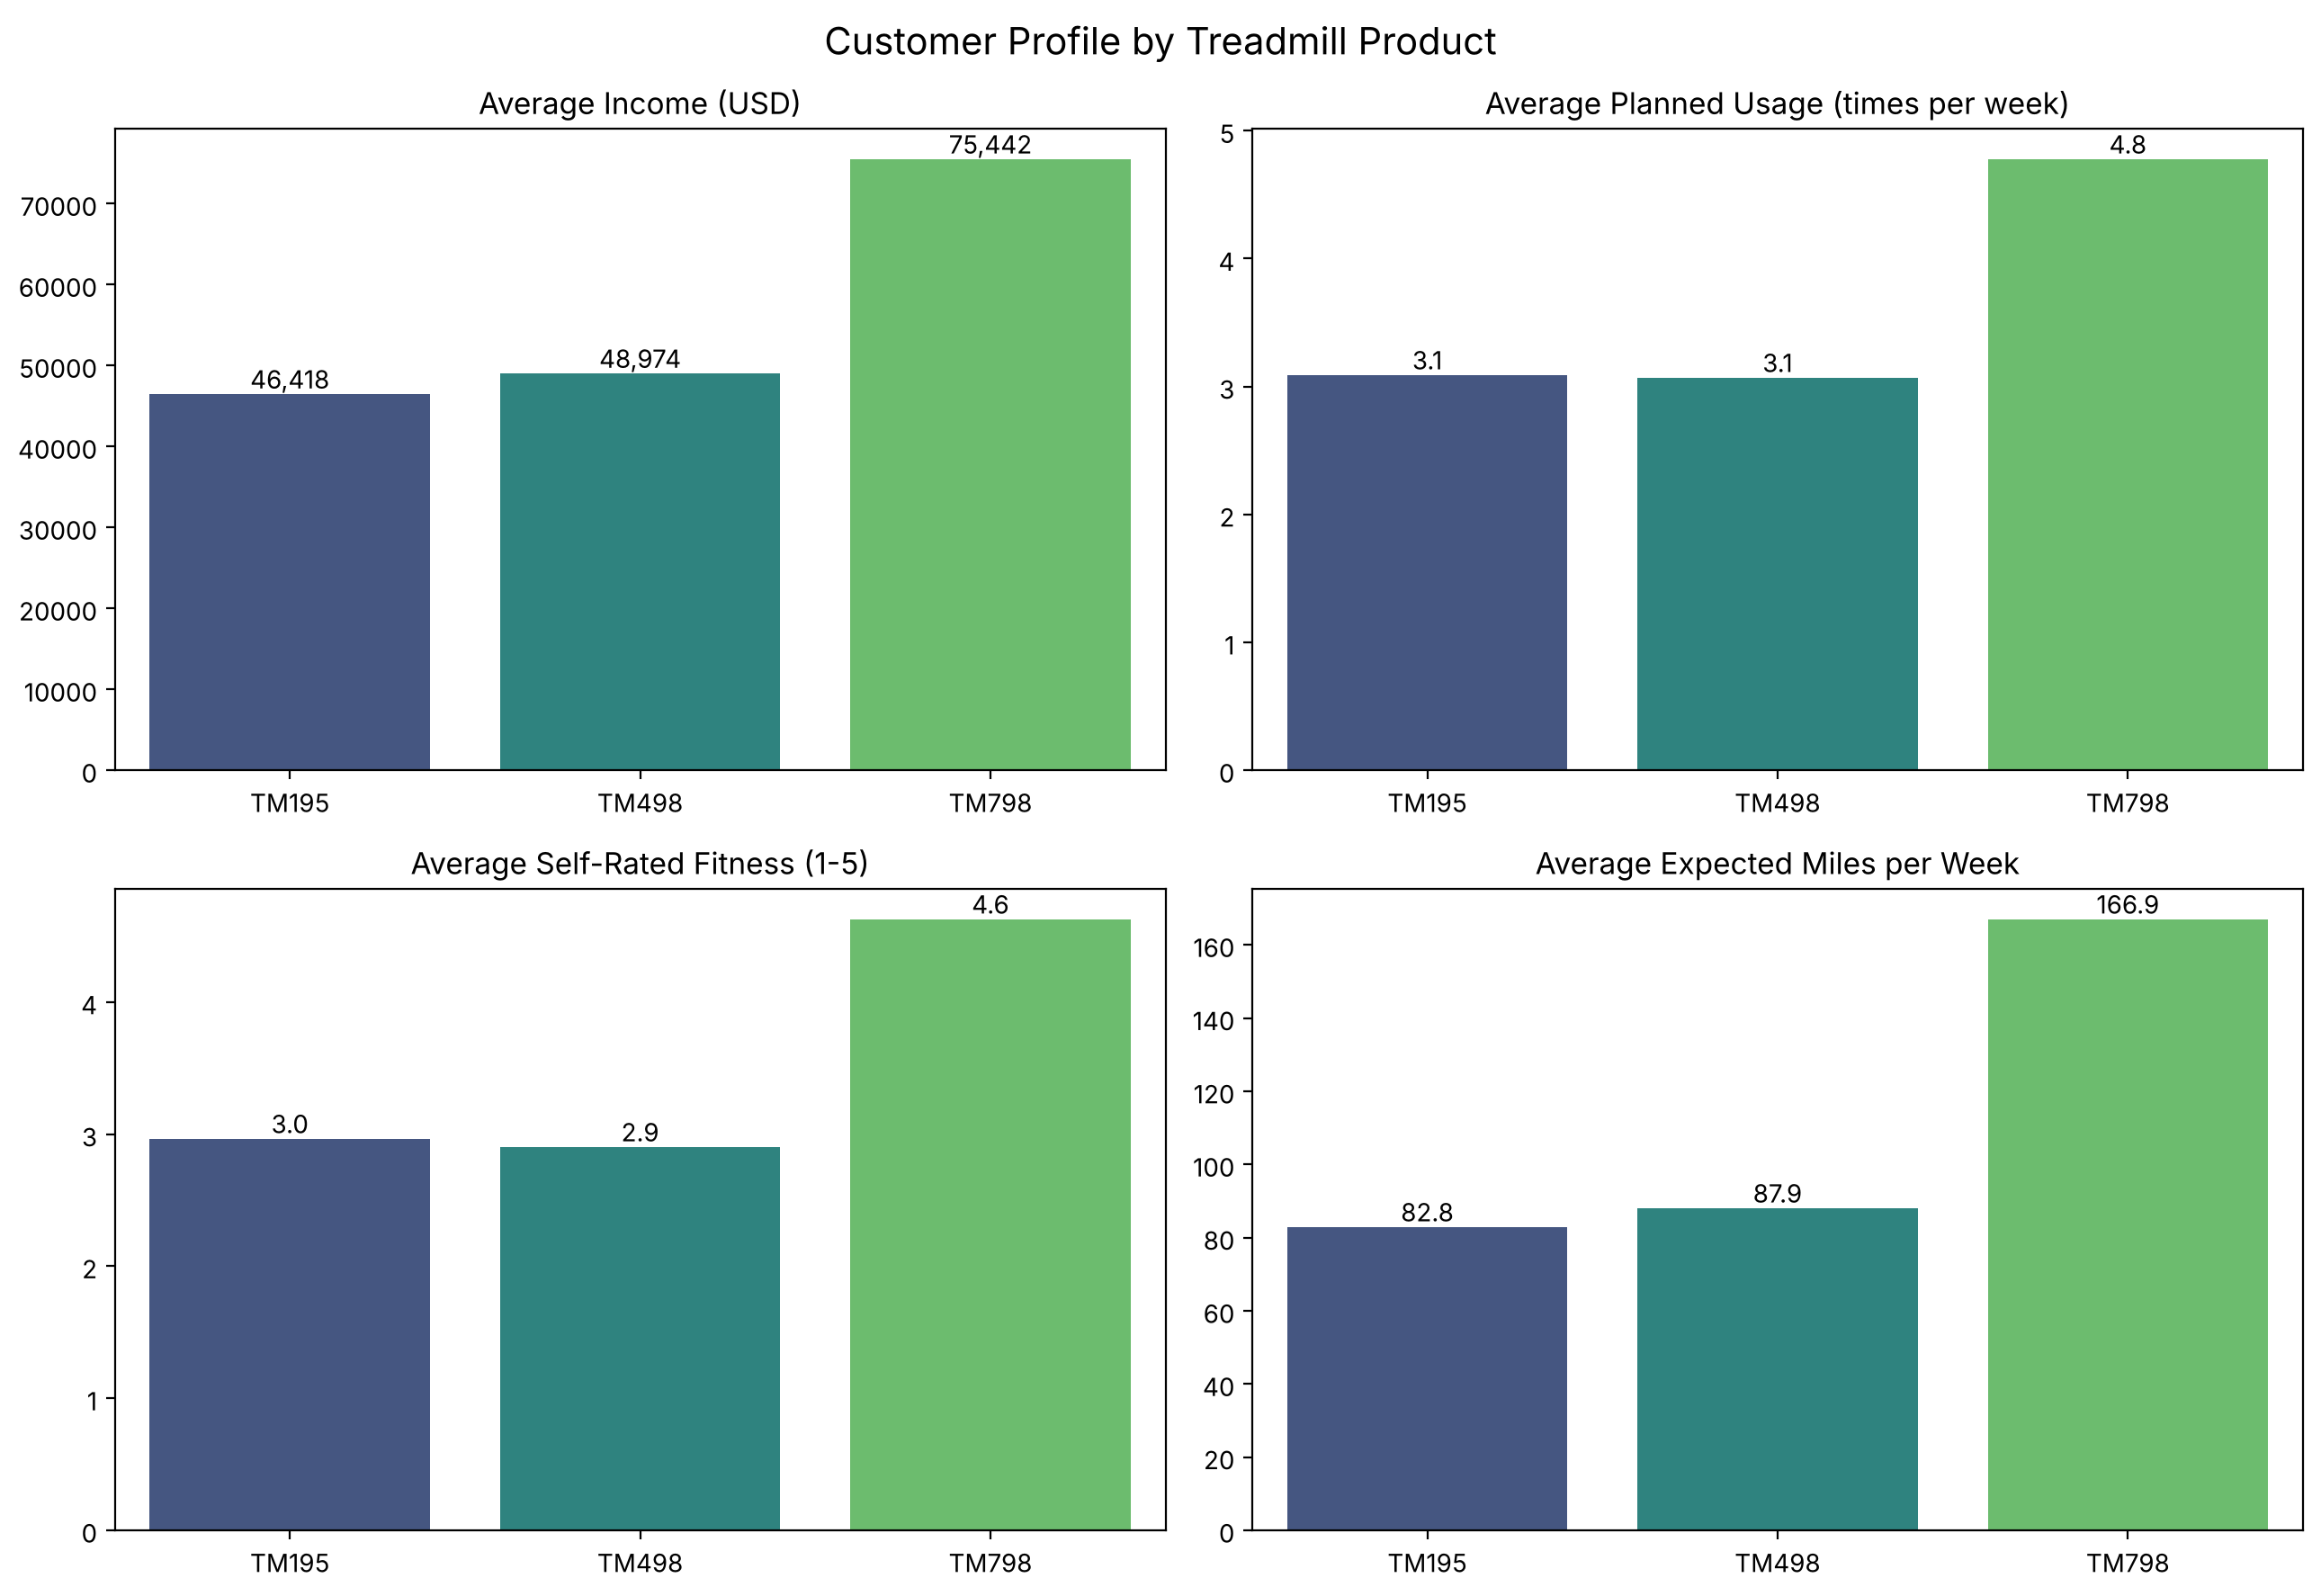

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (col, title) in zip(axes.ravel(), [("Income", "Average Income (USD)"),
                                           ("Usage", "Average Planned Usage (times per week)"),
                                           ("Fitness", "Average Self-Rated Fitness (1-5)"),
                                           ("Miles", "Average Expected Miles per Week")]):
    means = mydata.groupby("Product")[col].mean()
    sns.barplot(x=means.index, y=means.values, hue=means.index, palette="viridis", legend=False, ax=ax)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("")
    for i, v in enumerate(means.values):
        ax.text(i, v, f"{v:,.1f}" if col != "Income" else f"{v:,.0f}", ha="center", va="bottom")
plt.suptitle("Customer Profile by Treadmill Product", fontsize=15)
plt.tight_layout()
plt.show()

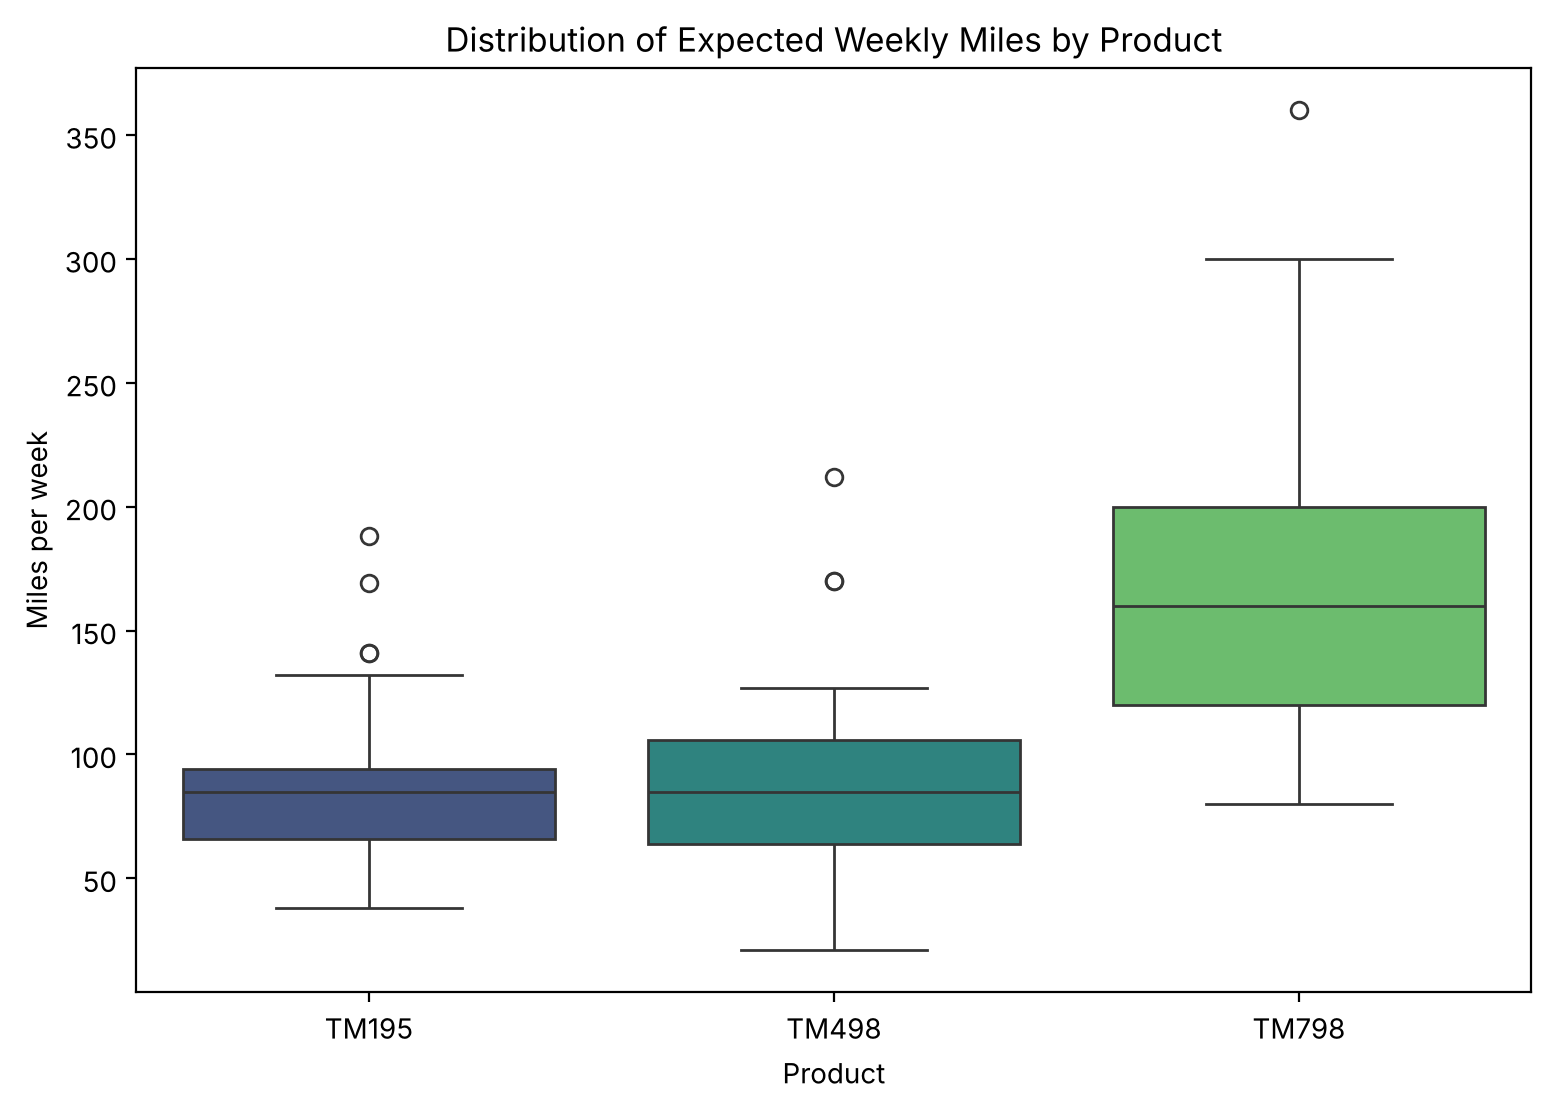

In [27]:
plt.figure(figsize=(9, 6))
sns.boxplot(x="Product", y="Miles", hue="Product", data=mydata, palette="viridis", legend=False)
plt.title("Distribution of Expected Weekly Miles by Product")
plt.ylabel("Miles per week")
plt.show()

In [28]:
from scipy import stats

print("Chi-square tests of independence (Product vs. ...)")
for col in ["Gender", "MaritalStatus"]:
    table = pd.crosstab(mydata["Product"], mydata[col])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    print(f"  {col:<14} chi2 = {chi2:5.2f}, dof = {dof}, p = {p:.4f}, Cramer's V = {v:.2f}, min expected count = {expected.min():.1f}")

print("\nOne-way ANOVA across products")
for col in ["Age", "Education", "Income", "Usage", "Fitness", "Miles"]:
    f, p = stats.f_oneway(*[g[col].values for _, g in mydata.groupby("Product")])
    print(f"  {col:<10} F = {f:6.2f}, p = {p:.2e}")

print("\nTukey HSD pairwise comparisons (p-values)")
groups = {name: g for name, g in mydata.groupby("Product")}
names = list(groups)
for col in ["Income", "Miles", "Usage", "Fitness"]:
    res = stats.tukey_hsd(*[groups[n][col] for n in names])
    pairs = [(0, 1), (0, 2), (1, 2)]
    print(f"  {col:<8}", " | ".join(f"{names[i]} vs {names[j]}: p = {res.pvalue[i][j]:.3f}" for i, j in pairs))

Chi-square tests of independence (Product vs. ...)
  Gender         chi2 = 12.92, dof = 2, p = 0.0016, Cramer's V = 0.27, min expected count = 16.9
  MaritalStatus  chi2 =  0.08, dof = 2, p = 0.9605, Cramer's V = 0.02, min expected count = 16.2

One-way ANOVA across products
  Age        F =   0.09, p = 9.10e-01
  Education  F =  45.19, p = 1.40e-16
  Income     F =  89.26, p = 1.56e-27
  Usage      F =  65.44, p = 5.28e-22
  Fitness    F = 104.00, p = 1.36e-30
  Miles      F =  68.24, p = 1.07e-22

Tukey HSD pairwise comparisons (p-values)
  Income   TM195 vs TM498: p = 0.410 | TM195 vs TM798: p = 0.000 | TM498 vs TM798: p = 0.000
  Miles    TM195 vs TM498: p = 0.723 | TM195 vs TM798: p = 0.000 | TM498 vs TM798: p = 0.000
  Usage    TM195 vs TM498: p = 0.988 | TM195 vs TM798: p = 0.000 | TM498 vs TM798: p = 0.000
  Fitness  TM195 vs TM498: p = 0.842 | TM195 vs TM798: p = 0.000 | TM498 vs TM798: p = 0.000


**What the tests show.**

- **Gender** is associated with product (chi-square = 12.92, p = 0.002, Cramer's V = 0.27): TM798 skews male.
- **Marital status** is *not* associated with product (chi-square = 0.08, p = 0.96); about 60% of buyers are partnered for every product.
- **Age** does not differ across products (ANOVA p = 0.91).
- **Education, Income, Usage, Fitness and Miles** all differ significantly across products (p < 0.001).
- The pairwise tests show that **TM798 differs from both other products on income, miles, usage and fitness (all p < 0.001), whereas TM195 and TM498 do not differ from each other on any of them** (p between 0.41 and 0.99).

### The typical customer for each product

| | TM195 | TM498 | TM798 |
|---|---|---|---|
| **Share of customers** | 80 (44%) | 60 (33%) | 40 (22%) |
| **Profile** | Casual, entry-level | Casual, mid-range | Serious, high-performance |
| Age | 28.6 | 28.9 | 29.1 |
| Gender | 50% female | 48% female | **18% female (82% male)** |
| Education (years) | 15.0 | 15.1 | **17.3** |
| Income | \$46.4k | \$49.0k | **\$75.4k** |
| Planned usage (per week) | 3.1 | 3.1 | **4.8** |
| Self-rated fitness (1-5) | 3.0 | 2.9 | **4.6** |
| Expected miles per week | 82.8 | 87.9 | **166.9** |

All 23 customers with income above \$70k bought a TM798 (as did all 21 above \$75k), and 29 of the 31 customers who rate their fitness 5 bought a TM798.

In [29]:
#simple Linear Regression

#Load Function from sklearn
from sklearn import linear_model

#creat Linear regression object
regr = linear_model.LinearRegression()
y =mydata['Miles']
x = mydata[['Usage', 'Fitness']]

#fit the model
regr.fit(x,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[20.21,27.21]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Usage','Fitness']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-56.74
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [30]:
regr.coef_

array([20.21486334, 27.20649954])

In [31]:
regr.intercept_

np.float64(-56.74288178464862)

In [32]:
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import cross_val_score
import statsmodels.api as sm

pred = regr.predict(x)
print(f"R-squared (in-sample): {r2_score(y, pred):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y, pred)):.1f} miles per week")

cv = cross_val_score(linear_model.LinearRegression(), x, y, cv=5, scoring="r2")
print(f"5-fold cross-validated R-squared: mean {cv.mean():.2f} (range {cv.min():.2f} to {cv.max():.2f})")

ols = sm.OLS(y, sm.add_constant(x)).fit()
print("\nCoefficient p-values:")
print(ols.pvalues.round(6).to_string())

R-squared (in-sample): 0.716
RMSE: 27.6 miles per week
5-fold cross-validated R-squared: mean 0.61 (range 0.26 to 0.82)

Coefficient p-values:
const      0.0
Usage      0.0
Fitness    0.0


**Regression interpretation.** Holding Fitness fixed, each extra planned weekly session is associated with about **20 more expected miles**, and holding Usage fixed, each extra fitness point with about **27 more miles**. Both coefficients are statistically significant (p < 0.001). The model explains **71.6%** of the variation in miles in-sample (adjusted R-squared about 0.71, typical error about 28 miles per week). On held-out folds the R-squared averages **0.61** and ranges from 0.26 to 0.82, so with only 180 customers the fit is less stable than the in-sample figure suggests. The negative intercept has no practical meaning, because no customer plans zero usage. Usage and Fitness are correlated (0.67), so the individual coefficients should be interpreted with care. This describes expected miles of buyers; it is not a model for predicting who will buy.

### Fitted regression equation

$$\text{Miles}_{\text{predicted}} = -56.74 + 20.21 \times \text{Usage} + 27.21 \times \text{Fitness}$$

## Answers to the guiding questions

1. **What types of variables are in the data?** Six numeric (Age, Education, Usage, Fitness, Income, Miles; Usage and Fitness are ordinal scores) and three categorical (Product, Gender, MaritalStatus). There are no missing values.
2. **What do the distributions look like?** Age, Income and Miles are right-skewed. Most customers are in their 20s, plan to use the treadmill 3-4 times a week and rate their fitness as 3.
3. **Which product is more popular among males or females?** TM195 is the most purchased overall. Women and men buy TM195 and TM498 in near-equal numbers, but TM798 is bought mostly by men (33 of 40).
4. **Is purchase affected by marital status?** No. About 60% of buyers of every product are partnered (chi-square p = 0.96).
5. **Are there significant correlations?** Yes: Fitness-Miles (0.79), Usage-Miles (0.76), Usage-Fitness (0.67), Education-Income (0.63). Age is almost uncorrelated with the usage variables.
6. **What is the distribution of miles by product?** TM195 and TM498 are similar (median 85 miles per week each); TM798 is much higher (median 160), with the widest spread and the largest values (up to 360).

## Recommendations

1. **Position the TM798 as the premium, performance product** for higher-income (about \$75k+), highly fit customers who plan to train around 5 times a week, rather than marketing it broadly.
2. **Investigate the gender gap on TM798.** Only 18% of its buyers are women, versus about half for the other models. The data cannot say why (marketing reach, features, or preference), so test it with targeted campaigns and customer surveys before drawing conclusions.
3. **Treat TM195 and TM498 as one casual segment.** Their buyers are very similar on every measured attribute, and statistically indistinguishable on income, usage, fitness and miles. Make the difference between the two clear to customers through features or price, or consider simplifying the line-up. (This dataset has no price or feature information, so this needs to be tested.)
4. **Do not segment by age or marital status.** Neither separates the products.
5. **Guide buyers at the point of sale** with two questions, planned weekly usage and fitness level; they are the strongest signals of which tier a customer ends up buying.
6. **Collect richer data next:** non-buyers, price paid, satisfaction and repeat purchases, which would allow modelling of *who buys*, not just describing who bought.

## Limitations

- **Small sample:** 180 customers from a three-month window at CardioGood Fitness retail stores. Some segments are tiny (for example 7 women bought a TM798).
- **Buyers only:** the profiles describe who bought each product, not the wider market, and cannot show what *drives* a purchase.
- **Self-reported and forward-looking:** Usage, Miles and Fitness are customers' own expectations and ratings, not measured behaviour.
- **Overlapping drivers:** Income, Education, Fitness and Usage are correlated, so product differences on these cannot be cleanly separated from each other.
- **Association, not causation**, throughout. Outliers in Miles (above 200, mostly TM798 buyers) were kept in the analysis.